# Start Here: What Is AI? The Big Picture

> **Who is this for:** a complete beginner. You may have written a few lines of Python, or none at all. You know high-school math. Nothing else is assumed.
>
> **What you will learn**
> - What **AI**, **Machine Learning**, **Deep Learning**, **Generative AI** and **LLMs** are, and how they fit inside each other
> - The difference between *writing rules by hand* and *learning from data*
> - The 3 main kinds of learning: supervised, unsupervised and reinforcement learning
> - The key words you will meet in every other notebook (data, features, label, model, training, parameters, loss, prediction, train/test split, overfitting, inference)
> - What a neural network is, and what an LLM actually does (it predicts the next token)
> - How a real AI project runs from start to finish, and who does which job
> - A map of this whole repository, so you know where everything lives
>
> **Prerequisites:** none. This is the very first notebook. If Python is not installed yet, follow [`START_HERE.md`](../START_HERE.md) first.
>
> **Time needed:** about 60-90 minutes.
>
> **Runs on:** CPU, no API key. Everything runs offline on your own computer.

💡 **Tip:** you do not need to understand every line of code yet. Run each cell (click it, then press **Shift + Enter**) and read the "**What just happened?**" box under it. The Python notebooks in [`01_Python/`](../01_Python/) teach the code properly. The next notebook, [`01_Python/00_start_here_jupyter_terminal_and_debugging.ipynb`](../01_Python/00_start_here_jupyter_terminal_and_debugging.ipynb), explains how notebooks work.

## Contents

1. What AI, ML, Deep Learning, Generative AI and LLMs are
2. Rules vs learning from data (a spam filter, two ways)
3. The 3 main kinds of learning
4. Key vocabulary, one tiny example at a time
5. What a neural network is
6. What an LLM does: predict the next token
7. How a real AI project runs, and who does what
8. A map of this repository
9. Why ethics comes next
10. Recap, exercises, where to go next

## 1. What are AI, ML, Deep Learning, Generative AI and LLMs?

These five words are often used as if they meant the same thing. They don't. Each one is a *smaller box inside the one before it*.

| Term | Plain-English meaning | Everyday example |
|---|---|---|
| **Artificial Intelligence (AI)** | Any computer system that does a task we would normally say needs human intelligence: deciding, recognising, planning, understanding language. | A chess program, a route planner, a spam filter |
| **Machine Learning (ML)** | A kind of AI where the computer **learns the rules from examples (data)** instead of a person writing every rule by hand. | A spam filter that learned from thousands of emails marked "spam" or "not spam" |
| **Deep Learning (DL)** | A kind of ML that uses **neural networks** with many layers (that is what "deep" means). Very good with messy data like images, sound and text. | Face unlock on a phone, speech-to-text |
| **Generative AI (GenAI)** | AI that **creates new content** (text, images, audio, code) instead of only labelling or predicting a number. Most modern GenAI is built with deep learning. | Making a picture from a sentence, writing a draft email |
| **Large Language Model (LLM)** | A very large deep-learning model trained on huge amounts of text to **predict the next piece of text**. Chat assistants are built on LLMs. | A chatbot that answers questions or summarises a document |

### How they nest

```
+--------------------------------------------------------------------+
|  ARTIFICIAL INTELLIGENCE  (any "smart" behaviour, incl. hand rules) |
|                                                                    |
|   +------------------------------------------------------------+   |
|   |  MACHINE LEARNING  (learns patterns from data)             |   |
|   |                                                            |   |
|   |   +----------------------------------------------------+   |   |
|   |   |  DEEP LEARNING  (many-layer neural networks)       |   |   |
|   |   |                                                    |   |   |
|   |   |   +--------------------------------------------+   |   |   |
|   |   |   |  GENERATIVE AI  (creates new content)      |   |   |   |
|   |   |   |                                            |   |   |   |
|   |   |   |   +------------------------------------+   |   |   |   |
|   |   |   |   |  LLMs  (generate text, token by    |   |   |   |   |
|   |   |   |   |         token)                     |   |   |   |   |
|   |   |   |   +------------------------------------+   |   |   |   |
|   |   |   +--------------------------------------------+   |   |   |
|   |   +----------------------------------------------------+   |   |
|   +------------------------------------------------------------+   |
+--------------------------------------------------------------------+
```

So: **every LLM is generative AI, which is deep learning, which is machine learning, which is AI**. But not the other way round: a hand-written chess program is AI and is *not* machine learning.

⚠️ **Common mistake:** thinking "AI" means "chatbot". Chatbots are only the innermost box. Most AI working in companies today is "plain" machine learning on tables of numbers: predicting sales, spotting fraud, recommending products.

### Setup: load the tools we use in this notebook

The next cell **imports** (loads) some free Python libraries:
- **NumPy**: fast maths on lists of numbers.
- **pandas**: tables of data (like a spreadsheet inside Python).
- **Matplotlib**: drawing charts.
- **scikit-learn** (imported as `sklearn`): ready-made machine-learning tools.

We also set a **random seed**. Some steps use random numbers; fixing the seed makes them come out the same every time you run the notebook, so your output matches the text.

In [1]:
import warnings                      # lets us hide noisy warning messages
warnings.filterwarnings("ignore")    # keep the output clean for beginners

import numpy as np                   # maths on arrays of numbers
import pandas as pd                  # tables (DataFrames)
import matplotlib.pyplot as plt      # charts

SEED = 42                            # any fixed number works; 42 is a tradition
rng = np.random.default_rng(SEED)    # our random-number generator, seeded

pd.set_option("display.width", 120)  # show wide tables without wrapping
print("Libraries loaded. NumPy", np.__version__, "| pandas", pd.__version__)

Libraries loaded. NumPy 2.4.6 | pandas 2.3.3


**What just happened?** Python loaded the libraries and printed their version numbers. Your versions may be slightly different; that is fine. If you instead see `ModuleNotFoundError`, the libraries are not installed yet: see [`START_HERE.md`](../START_HERE.md).

## 2. Rules vs learning from data

Imagine you must build a **spam filter**: a program that decides whether a message is junk ("spam") or a normal message (often called "ham").

There are two ways to do it:

| Approach | How it works | Good at | Bad at |
|---|---|---|---|
| **Hand-written rules** (classic programming) | A person writes `if` statements: *"if the message contains 'free', call it spam"*. | Simple, predictable, easy to explain | Breaks on anything the person did not think of; endless rule-writing |
| **Learning from data** (machine learning) | We collect example messages that people already marked as spam or ham, and let an algorithm find the patterns itself. | Finds patterns humans miss; improves with more data | Needs good, honest example data; harder to explain |

Classic programming: **rules + data → answers**. Machine learning: **data + answers → rules** (the learned "rules" are called a **model**).

First, a small made-up set of messages. Each one already has the correct answer: `1` = spam, `0` = ham.

In [2]:
# A tiny, made-up dataset: 20 messages, each marked by a human
messages = [
    ("Win a FREE prize now, click here", 1),
    ("Claim your cash reward today", 1),
    ("You are a winner, claim your prize", 1),
    ("Cheap loans, click to apply now", 1),
    ("Exclusive offer: cash bonus for you", 1),
    ("Your reward is waiting, claim now", 1),
    ("Get free cash fast, limited offer", 1),
    ("Urgent: claim your bonus reward", 1),
    ("Winner! Click to get your cash", 1),
    ("Limited time offer, apply today", 1),
    ("Are we still meeting for lunch tomorrow?", 0),
    ("Can you send me the report by Friday?", 0),
    ("Happy birthday! See you at dinner", 0),
    ("The meeting moved to 3pm today", 0),
    ("Thanks for the help with the project", 0),
    ("Lunch at noon? I can book a table", 0),
    ("Please review my notes before class", 0),
    ("Dinner tomorrow with the team?", 0),
    ("I left the keys at your place", 0),
    ("See you at the project meeting", 0),
]
df = pd.DataFrame(messages, columns=["text", "is_spam"])  # turn the list into a table
print(df.shape)          # (rows, columns)
df.head(4)               # show the first 4 rows

(20, 2)


,text,is_spam
0,"Win a FREE prize now, click here",1
1,Claim your cash reward today,1
2,"You are a winner, claim your prize",1
3,"Cheap loans, click to apply now",1


**What just happened?** We built a table with **20 rows** (messages) and **2 columns**: the message `text` and the human answer `is_spam`. Ten are spam and ten are ham. Real spam filters learn from millions of messages; 20 is only enough to show the idea.

### Approach A: hand-written rules

In [3]:
SPAM_WORDS = ["free", "winner", "prize", "click"]   # words a human decided are "spammy"

def rule_based_filter(text):
    "Return 1 (spam) if any spam word appears in the text, else 0 (ham)."
    lowered = text.lower()                           # ignore UPPER/lower case
    return int(any(word in lowered for word in SPAM_WORDS))

# Four NEW messages the filter has never seen
new_messages = [
    "Claim your cash reward now",          # spam, but uses none of our words
    "Are you free for lunch tomorrow?",    # ham, but contains the word 'free'
    "You are a winner! Click for your prize",  # obvious spam
    "The project meeting is at noon",      # obvious ham
]
for msg in new_messages:
    print(rule_based_filter(msg), "<-", msg)

0 <- Claim your cash reward now
1 <- Are you free for lunch tomorrow?
1 <- You are a winner! Click for your prize
0 <- The project meeting is at noon


**What just happened?** The rule filter got the two obvious messages right, but:
- it **missed** "Claim your cash reward now" (spam with none of our four words) and
- it **wrongly flagged** "Are you free for lunch tomorrow?" because it contains "free".

We could keep adding rules forever ("free *but not* free for lunch..."). This is exactly the problem machine learning solves.

### Approach B: learn from the examples

We use two scikit-learn tools:
- **`CountVectorizer`** turns each message into numbers: how many times each word appears. Computers need numbers, not text.
- **`MultinomialNB`** (Naive Bayes) is a simple, classic model for text. It learns how often each word appears in spam versus ham.

In [4]:
from sklearn.feature_extraction.text import CountVectorizer   # text -> word counts
from sklearn.naive_bayes import MultinomialNB                  # a simple text model
from sklearn.pipeline import make_pipeline                     # chain the two steps

learned_filter = make_pipeline(CountVectorizer(), MultinomialNB())  # step 1 then step 2
learned_filter.fit(df["text"], df["is_spam"])     # LEARN from the 20 labelled messages

comparison = pd.DataFrame({
    "message": new_messages,
    "rules": [rule_based_filter(m) for m in new_messages],   # approach A
    "learned": learned_filter.predict(new_messages),         # approach B
    "truth": [1, 0, 1, 0],                                    # what a human would say
})
comparison

,message,rules,learned,truth
0,Claim your cash reward now,0,1,1
1,Are you free for lunch tomorrow?,1,0,0
2,You are a winner! Click for your prize,1,1,1
3,The project meeting is at noon,0,0,0


**What just happened?** `.fit(...)` is where the learning happens: the model looked at the 20 examples and worked out which words go with spam. Then `.predict(...)` gave answers for the 4 new messages.

You should see the **learned** column matching the **truth** column on all four, while the **rules** column gets two wrong. Nobody told the model that "claim", "cash" or "reward" are spammy; it discovered that from the data. And because "lunch" and "tomorrow" appeared in normal messages, one word "free" was not enough to call the lunch message spam.

⚠️ **Common mistake:** concluding "learning always beats rules". With only 20 examples this model is fragile, and a single unusual message can fool it. In real systems people often **combine** both: learned models plus a few hard rules for safety.

## 3. The 3 main kinds of learning

| Kind | What the data looks like | The question it answers | Everyday analogy |
|---|---|---|---|
| **Supervised learning** | Examples **with the right answer** attached (a **label**) | "Given this input, what is the answer?" | Studying with an answer key |
| **Unsupervised learning** | Examples **without answers** | "What groups or structure are hidden in here?" | Sorting a box of mixed buttons into piles that look alike |
| **Reinforcement learning (RL)** | No examples at all; an **agent** tries actions and gets **rewards** | "Which actions earn the most reward over time?" | Training a dog with treats; learning a video game by playing |

The spam filter above was **supervised** (each message had a spam/ham label). Here is a tiny runnable example of each kind.

### 3a. Supervised: fit a line (hours studied → exam score)

In [5]:
from sklearn.linear_model import LinearRegression

hours = np.array([[1], [2], [3], [4], [5], [6]])     # input: hours studied (one column)
scores = np.array([52, 55, 61, 64, 70, 73])          # label: exam score (the answer key)
line = LinearRegression().fit(hours, scores)         # learn the best straight line
print("Predicted score after 7 hours:", line.predict([[7]]).round(1))

Predicted score after 7 hours: [77.8]


**What just happened?** We gave the model 6 examples *with answers*. It found the straight line that best fits them and used it to predict a score for 7 hours of study (about **78**). Predicting a **number** like this is called **regression**. Predicting a **category** (spam / ham) is called **classification**. Both are supervised learning.

### 3b. Unsupervised: find groups (clustering) with KMeans

Points in each group found: [50 50 50]


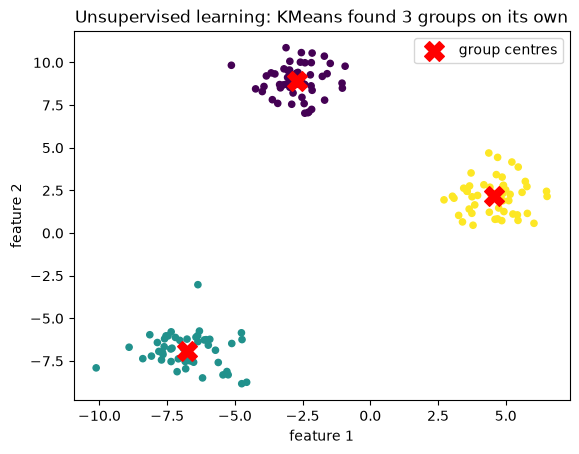

In [6]:
from sklearn.datasets import make_blobs     # makes fake 2-D points in clumps
from sklearn.cluster import KMeans          # a classic grouping (clustering) method

points, _ = make_blobs(n_samples=150, centers=3, random_state=SEED)  # we THROW AWAY the true groups (_)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(points)  # ask for 3 groups
print("Points in each group found:", np.bincount(kmeans.labels_))

plt.scatter(points[:, 0], points[:, 1], c=kmeans.labels_, cmap="viridis", s=20)
plt.scatter(*kmeans.cluster_centers_.T, c="red", marker="X", s=200, label="group centres")
plt.title("Unsupervised learning: KMeans found 3 groups on its own")
plt.xlabel("feature 1"); plt.ylabel("feature 2"); plt.legend(); plt.show()

**What just happened?** The model got 150 points with **no labels** and was only told "find 3 groups". It found three clumps of about 50 points each (colours) and marked each group's centre with a red **X**. Companies use the same idea to group customers with similar shopping habits ("customer segmentation").

### 3c. Reinforcement: learn by trial and error (a 3-slot-machine game)

Three slot machines pay out with different (secret) chances. The agent does not know which is best. Each turn it either **explores** (tries a random machine, 10% of the time) or **exploits** (plays the machine that has paid best so far). This tiny game is called a **multi-armed bandit**.

In [7]:
true_win_chance = [0.2, 0.5, 0.8]        # secret! the agent never sees this list
estimates, pulls = np.zeros(3), np.zeros(3)   # agent's running guess and play counts per machine
for turn in range(500):
    arm = rng.integers(3) if rng.random() < 0.1 else int(np.argmax(estimates))  # explore or exploit
    reward = float(rng.random() < true_win_chance[arm])                         # 1 = win, 0 = lose
    pulls[arm] += 1; estimates[arm] += (reward - estimates[arm]) / pulls[arm]   # update running average
print("Estimated win chance:", estimates.round(2), "| times played:", pulls.astype(int))

Estimated win chance: [0.16 0.57 0.79] | times played: [ 44  23 433]


**What just happened?** Nobody gave the agent examples or answers; it only saw the rewards from its own actions. After 500 turns it plays machine 3 (the best one, 80% win chance) far more often than the others, and its estimated win chances are close to the secret values. Your exact numbers depend on the random seed. This trial-and-error idea is the heart of **reinforcement learning**, used for game-playing AIs, robots, and to help tune LLMs with human feedback. See [`11_Reinforcement_Learning/`](../11_Reinforcement_Learning/).

💡 **Tip:** if you can't tell which kind a problem is, ask: *"Do I have the right answers for my examples?"* Yes → supervised. No → unsupervised. "I only find out afterwards whether an action was good" → reinforcement.

## 4. Key vocabulary, one tiny example at a time

We'll use one small made-up problem for all the words: **predicting a house price from its size and number of rooms**.

### Data, features and label

- **Data**: the collection of examples we learn from (here, a table of houses).
- **Features**: the *inputs* that describe each example (size, rooms). Also called *inputs*, *variables* or *columns*. Often written `X`.
- **Label**: the *answer* we want to predict (price). Also called the *target*. Often written `y`.

In [8]:
n = 60                                                     # 60 made-up houses
size_m2 = rng.uniform(40, 200, n).round()                  # size in square metres
rooms = np.clip((size_m2 / 35).round() + rng.integers(-1, 2, n), 1, None)  # bigger -> more rooms
price_k = (1.5 * size_m2 + 10 * rooms + 30 + rng.normal(0, 15, n)).round()  # price in thousands + noise

houses = pd.DataFrame({"size_m2": size_m2, "rooms": rooms, "price_k": price_k})
X = houses[["size_m2", "rooms"]]     # FEATURES: the inputs
y = houses["price_k"]                # LABEL: the answer we want to predict
print("X (features) shape:", X.shape, "| y (label) shape:", y.shape)
houses.head()

X (features) shape: (60, 2) | y (label) shape: (60,)


,size_m2,rooms,price_k
0,99.0,3.0,215.0
1,158.0,4.0,308.0
2,105.0,4.0,229.0
3,130.0,3.0,249.0
4,155.0,4.0,282.0


**What just happened?** We made a table of 60 houses. `X` has 60 rows and 2 feature columns; `y` has 60 prices. Each **row** is one example (one house). We secretly built the prices as roughly "1.5 × size + 10 × rooms + 30, plus random noise", so we know what a good model *should* discover.

### Train/test split

If you let students see the exam questions while studying, a perfect exam score proves nothing. Same in ML: we **hide some data** while training, and use it only at the end to check the model honestly.

- **Training set**: the examples the model learns from.
- **Test set**: examples kept aside to measure how well the model does on data it has **never seen**.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED)       # keep 25% of houses hidden for testing
print("Training houses:", len(X_train), "| Test houses:", len(X_test))

Training houses: 45 | Test houses: 15


**What just happened?** The 60 houses were shuffled and split: **45** for training, **15** kept aside for testing.

### Model, training and parameters

- **Model**: the "recipe" that turns features into a prediction. Here: a straight-line formula, `price = a × size + b × rooms + c`.
- **Parameters**: the numbers inside the model that get learned (`a`, `b`, `c`). Big models have millions or billions of them.
- **Training** (also called *fitting*): the process of finding good parameter values from the training data.

In [10]:
model = LinearRegression()            # MODEL: price = a*size + b*rooms + c
model.fit(X_train, y_train)           # TRAINING: find good values for a, b and c

a, b = model.coef_                    # PARAMETERS learned for each feature
c = model.intercept_                  # PARAMETER: the starting value
print(f"Learned formula: price = {a:.2f} * size + {b:.2f} * rooms + {c:.1f}")

Learned formula: price = 1.61 * size + 5.77 * rooms + 32.9


**What just happened?** Training found parameter values for our formula. The number for size should be close to the secret 1.5 per square metre. The number for rooms is less exact (you may see something like 6 instead of 10). That is because of the random noise, and because size and rooms move together (bigger houses have more rooms), so the model can trade a little credit between them. The model never saw our recipe; it worked these numbers out from just 45 examples.

### Loss

- **Loss**: a single number measuring **how wrong** the model's predictions are. Training means *"change the parameters to make the loss smaller"*.
- A common loss for numbers is the **mean squared error (MSE)**: take each error (prediction minus truth), square it (so negatives don't cancel positives), and average.

Let's compare the loss of a bad guess with the learned model.

In [11]:
def mse(predictions, truth):
    "Mean squared error: the average of (error squared)."
    return float(np.mean((np.asarray(predictions) - np.asarray(truth)) ** 2))

bad_guess = 1.0 * X_train["size_m2"] + 0 * X_train["rooms"] + 0     # someone's rough guess
print("Loss of the bad guess   :", round(mse(bad_guess, y_train)))
print("Loss of the learned model:", round(mse(model.predict(X_train), y_train)))

Loss of the bad guess   : 18302
Loss of the learned model: 202


**What just happened?** The rough guess ("price = 1 × size") has a much **bigger loss** than the trained model. Training is a search for parameters with the smallest loss. Our learned model's loss is roughly the size of the noise we added (15² = 225), which is about as good as any model can do here.

### Prediction and inference

- **Prediction**: the model's output for one example.
- **Inference**: *using* a trained model to make predictions on new data. Training happens once (or occasionally); inference happens every time someone uses the model, for example each time an app shows a price estimate.

Now we use the **test set** (the hidden houses) to see how good the predictions really are.

In [12]:
from sklearn.metrics import mean_absolute_error

test_predictions = model.predict(X_test)                       # INFERENCE on unseen houses
print("Average error on test houses: ±", round(mean_absolute_error(y_test, test_predictions), 1), "thousand")

new_house = pd.DataFrame({"size_m2": [120], "rooms": [4]})     # a brand-new house
print("Predicted price for 120 m², 4 rooms:", model.predict(new_house).round(1), "thousand")

Average error on test houses: ± 9.5 thousand
Predicted price for 120 m², 4 rooms: [249.6] thousand


**What just happened?** On the 15 hidden test houses, predictions are off by about 10 thousand on average, close to the amount of random noise we put in. Then we predicted a price for a completely new house (about 250 thousand). That last line *is* inference: exactly what a deployed model does all day.

### Overfitting (and underfitting)

- **Underfitting**: the model is **too simple** to capture the pattern. It does badly on training *and* test data.
- **Overfitting**: the model is **too flexible** and memorises the training data, including its random noise. It looks great on training data but does badly on new data. Like a student who memorised last year's exam answers without understanding.
- **Good fit**: in between: it captures the real pattern but not the noise.

We fit curves of increasing flexibility (**polynomials** of degree 1, 4 and 15; higher degree = more wiggly) to 20 noisy points that follow a wave.

degree  1: train loss = 0.175, test loss = 0.193


degree  4: train loss = 0.038, test loss = 0.084


degree 15: train loss = 0.026, test loss = 0.783


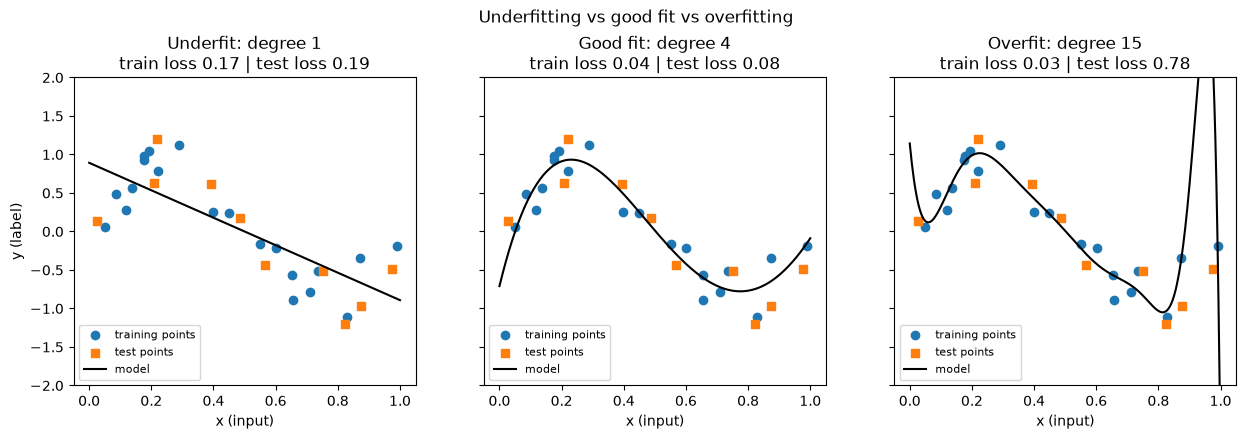

In [13]:
from sklearn.preprocessing import PolynomialFeatures

x_all = np.sort(rng.uniform(0, 1, 30))                           # 30 x-values between 0 and 1
y_all = np.sin(2 * np.pi * x_all) + rng.normal(0, 0.25, 30)      # a wave + noise
x_tr, x_te, y_tr, y_te = train_test_split(x_all, y_all, test_size=10, random_state=SEED)
grid = np.linspace(0, 1, 300)                                    # smooth x-values for drawing curves

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, degree, name in zip(axes, [1, 4, 15], ["Underfit", "Good fit", "Overfit"]):
    curve = make_pipeline(PolynomialFeatures(degree), LinearRegression()).fit(x_tr[:, None], y_tr)
    train_err, test_err = mse(curve.predict(x_tr[:, None]), y_tr), mse(curve.predict(x_te[:, None]), y_te)
    ax.scatter(x_tr, y_tr, label="training points"); ax.scatter(x_te, y_te, marker="s", label="test points")
    ax.plot(grid, curve.predict(grid[:, None]), "k-", label="model")
    ax.set_ylim(-2, 2); ax.set_xlabel("x (input)"); ax.legend(loc="lower left", fontsize=8)
    ax.set_title(f"{name}: degree {degree}\ntrain loss {train_err:.2f} | test loss {test_err:.2f}")
    print(f"degree {degree:>2}: train loss = {train_err:.3f}, test loss = {test_err:.3f}")
axes[0].set_ylabel("y (label)")
plt.suptitle("Underfitting vs good fit vs overfitting", y=1.05); plt.show()

**What just happened?** Look at the three panels and the printed numbers:
- **Degree 1 (underfit)**: a straight line cannot follow a wave. Both train and test loss are high.
- **Degree 4 (good fit)**: follows the wave. Train and test loss are both low and close to each other.
- **Degree 15 (overfit)**: wiggles wildly to pass near every training point. Its **training** loss is the smallest of the three, but its **test** loss is much bigger: it memorised noise.

The lesson: **always judge a model on data it did not train on.** A tiny training loss alone means nothing.

### Vocabulary summary

| Word | One-line meaning | In our house example |
|---|---|---|
| **Data** | The examples we learn from | The table of 60 houses |
| **Feature** | An input describing an example | `size_m2`, `rooms` |
| **Label** | The answer to predict | `price_k` |
| **Model** | The recipe from features to prediction | `price = a·size + b·rooms + c` |
| **Parameters** | Numbers inside the model that are learned | `a`, `b`, `c` |
| **Training** | Finding good parameters from data | `model.fit(X_train, y_train)` |
| **Loss** | How wrong the model is (smaller is better) | Mean squared error |
| **Prediction** | The model's output for one example | Price for a 120 m² house |
| **Train/test split** | Keeping some data hidden for an honest check | 45 train, 15 test houses |
| **Overfitting** | Memorising training data, failing on new data | The degree-15 curve |
| **Inference** | Using a trained model on new data | `model.predict(new_house)` |

The repo's [`GLOSSARY.md`](../GLOSSARY.md) explains many more terms in the same plain style.

## 5. What is a neural network?

A **neural network** is a model made of many tiny calculators called **neurons**, arranged in **layers**. Each neuron takes some numbers in, multiplies each by a **weight** (a parameter), adds them up, and passes the result through a simple "squash" function. Stacking layers lets the network build complex patterns out of simple ones.

```
   INPUT LAYER        HIDDEN LAYERS             OUTPUT LAYER
  (the features)   (learned in-between steps)   (the prediction)

   feature 1 o------>o------>o
                 \  / \    / \
                  \/   \  /   \
                  /\    \/     >-----> o  "class A" or "class B"
                 /  \   /\    /
   feature 2 o------>o------>o

   Every arrow ---> has a weight (a parameter) that training adjusts.
```

**Deep learning** just means neural networks with *many* hidden layers. The LLM later in this notebook has around half a billion parameters; the one below has a few hundred.

Let's see why the extra flexibility matters. The data is two interlocking half-moons: a straight line cannot separate them, but a small neural network can bend its boundary. We use scikit-learn's **`MLPClassifier`** (MLP = *multi-layer perceptron*, the classic neural network).

In [14]:
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression     # a straight-line classifier
from sklearn.neural_network import MLPClassifier        # a small neural network

Xm, ym = make_moons(n_samples=400, noise=0.25, random_state=SEED)     # two interlocking moons
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.25, random_state=SEED)

straight = LogisticRegression().fit(Xm_tr, ym_tr)                      # can only draw a straight line
network = MLPClassifier(hidden_layer_sizes=(16, 16), max_iter=3000,    # 2 hidden layers of 16 neurons
                        random_state=SEED).fit(Xm_tr, ym_tr)
n_params = sum(w.size for w in network.coefs_) + sum(b.size for b in network.intercepts_)
print("Neural network parameters:", n_params)
print("Test accuracy, straight line   :", round(straight.score(Xm_te, ym_te), 3))
print("Test accuracy, neural network  :", round(network.score(Xm_te, ym_te), 3))

Neural network parameters: 337
Test accuracy, straight line   : 0.8
Test accuracy, neural network  : 0.92


**What just happened?** Both models learned from 300 points and were tested on 100 unseen points. **Accuracy** is the fraction of test points classified correctly. The neural network (337 parameters) should score noticeably higher than the straight line: about 0.92 vs 0.80 here. The picture below shows why.

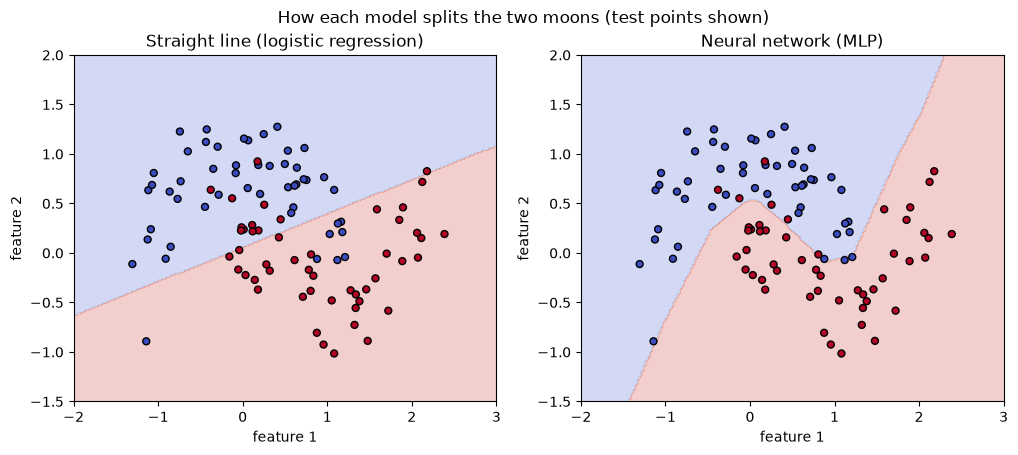

In [15]:
xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))   # a grid covering the plot
grid_points = np.c_[xx.ravel(), yy.ravel()]                                 # every grid point as (x, y)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, clf, title in zip(axes, [straight, network], ["Straight line (logistic regression)", "Neural network (MLP)"]):
    zone = clf.predict(grid_points).reshape(xx.shape)                       # which class each grid point gets
    ax.contourf(xx, yy, zone, alpha=0.25, cmap="coolwarm")                  # shade the two decision zones
    ax.scatter(Xm_te[:, 0], Xm_te[:, 1], c=ym_te, cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(title); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
plt.suptitle("How each model splits the two moons (test points shown)"); plt.show()

**What just happened?** The shaded areas show which class each model would predict at every spot. The straight-line model can only cut the plane in two with one straight line, so it misclassifies the tips of each moon. The neural network learned a **curved boundary** that follows the moons. Real deep-learning models do the same thing with millions of inputs (pixels of an image, words of a sentence) instead of two. Full details: [`05_Deep_Learning/01_neural_network_fundamentals.ipynb`](../05_Deep_Learning/01_neural_network_fundamentals.ipynb).

## 6. What an LLM does: predict the next token

A **Large Language Model (LLM)** does one thing, over and over: **given some text, predict what comes next**.

- Text is first cut into **tokens**: small pieces that are often whole words, parts of words, or punctuation. (" Paris" with its leading space can be one token; a long rare word may be split into several.)
- For the next position, the model gives a **probability** (a chance between 0 and 1) to **every token in its vocabulary** (tens of thousands of them).
- To write an answer, it picks a token, adds it to the text, and repeats. One token at a time. That is **generation**.

Before using a real LLM, here is the same idea with simple counting: look at a tiny text and count which word follows "the".

In [16]:
from collections import Counter

tiny_text = ("the cat sat on the mat . the cat ate the fish . "
             "the dog sat on the rug . the cat slept")
words = tiny_text.split()                                     # split into words (our "tokens")
followers = Counter(nxt for cur, nxt in zip(words, words[1:]) if cur == "the")  # what comes after "the"?
total = sum(followers.values())
for word, count in followers.most_common():
    print(f"P(next = {word!r:7} | previous = 'the') = {count}/{total} = {count/total:.2f}")

P(next = 'cat'   | previous = 'the') = 3/7 = 0.43
P(next = 'mat'   | previous = 'the') = 1/7 = 0.14
P(next = 'fish'  | previous = 'the') = 1/7 = 0.14
P(next = 'dog'   | previous = 'the') = 1/7 = 0.14
P(next = 'rug'   | previous = 'the') = 1/7 = 0.14


**What just happened?** After the word "the", our tiny text continues with "cat" 3 times out of 7, so a counting model would say "cat" has probability **0.43** of coming next. That is a (very) small **language model**. A real LLM does the same job, but instead of counting it uses a huge neural network that looks at **all** the previous tokens, not just one word, and it learned from a vast amount of text.

### Now a real (small) LLM, running on your CPU

We use **Qwen2.5-0.5B-Instruct**, an openly available model with about half a billion parameters. It is small by LLM standards, so it runs on a laptop. It is loaded from your computer's local cache (no internet, no API key). If it is not downloaded on your machine, the cell prints a message and the notebook carries on.

💡 **Tip:** the first run takes a little while (loading about 1 GB of parameters into memory).

In [17]:
import os
_hf_hub = os.environ.get("HF_HUB_CACHE") or os.path.join(os.environ.get("HF_HOME") or os.path.join(os.path.expanduser("~"), ".cache", "huggingface"), "hub")
if all(os.path.isdir(os.path.join(_hf_hub, "models--" + m.replace("/", "--"))) for m in ['Qwen/Qwen2.5-0.5B-Instruct']):
    os.environ.setdefault("HF_HUB_OFFLINE", "1")   # model already downloaded: never touch the internet
# (if it is not downloaded yet, the first run downloads it once from Hugging Face)
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # quiet loading
os.environ["TRANSFORMERS_VERBOSITY"] = "error"     # only show real errors

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
llm_ready = False
try:
    import torch
    import transformers
    from transformers import AutoTokenizer, AutoModelForCausalLM
    transformers.utils.logging.disable_progress_bar()
    torch.manual_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)        # text <-> token numbers
    llm = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32)  # the network itself
    llm.eval()                                                   # "use" mode, not training mode
    llm_ready = True
    print(f"Loaded {MODEL_NAME}: {sum(p.numel() for p in llm.parameters())/1e6:.0f} million parameters")
except Exception as err:                                         # model not cached / library missing
    print("Could not load the LLM, skipping this demo. Reason:", type(err).__name__, str(err)[:150])

Loaded Qwen/Qwen2.5-0.5B-Instruct: 494 million parameters


**What just happened?** If the model is on your machine, you should see it loaded with about **494 million parameters** (about half a billion). A **tokenizer** was loaded too: it converts text to token numbers and back.

Next: show how the prompt is cut into tokens, then ask the model for its **top-5 guesses** for the next token after *"The capital of France is"*.

In [18]:
prompt = "The capital of France is"
if llm_ready:
    ids = tokenizer(prompt, return_tensors="pt")                        # text -> token ids
    print("Tokens:", [tokenizer.decode(t) for t in ids["input_ids"][0]])
    with torch.no_grad():                                               # no training, just predicting
        scores = llm(**ids).logits[0, -1]                               # one score per vocabulary token
    probs = torch.softmax(scores, dim=-1)                               # turn scores into probabilities
    top = torch.topk(probs, k=5)                                        # the 5 most likely next tokens
    table = pd.DataFrame({"next token": [repr(tokenizer.decode(int(i))) for i in top.indices],
                          "probability": top.values.numpy().round(3)})
    print("Vocabulary size:", probs.shape[0])
    display(table)
else:
    print("LLM not available: skipped.")

Tokens: ['The', ' capital', ' of', ' France', ' is']


Vocabulary size: 151936


,next token,probability
0,' Paris',0.302
1,' ______',0.123
2,':\n',0.066
3,':\n\n',0.058
4,' __',0.048


**What just happened?**
- The prompt was split into 5 tokens. Notice that most tokens include the space *before* the word.
- The model produced one probability for **every** token in its vocabulary (about 150 thousand of them) and we show the top 5.
- You should see **`' Paris'` as the top guess** (around 0.3 with this model). The other top guesses are things like blanks (`' ______'`) or a colon followed by a line break, because text on the internet often looks like a fill-in-the-blank quiz. The model is not "looking up" a fact; it learned that "Paris" very often follows this phrase.

Now let the model **generate** a short answer. This "Instruct" model was trained to follow a chat format, so we wrap the question with its **chat template** (special markers saying "the user says... now the assistant answers").

In [19]:
if llm_ready:
    chat = [{"role": "user", "content": "In one short sentence: what is the capital of France?"}]
    inputs = tokenizer.apply_chat_template(chat, add_generation_prompt=True,
                                           return_tensors="pt", return_dict=True)    # chat -> tokens
    with torch.no_grad():
        output = llm.generate(**inputs, max_new_tokens=30, do_sample=False)         # add up to 30 tokens, always the top pick
    new_tokens = output[0, inputs["input_ids"].shape[1]:]                            # keep only the new part
    print("Model answer:", tokenizer.decode(new_tokens, skip_special_tokens=True))
    print("Number of tokens generated:", len(new_tokens))
else:
    print("LLM not available: skipped.")

Model answer: The capital of France is Paris.
Number of tokens generated: 8


**What just happened?** `generate` ran the "predict the next token, add it, repeat" loop for us. With `do_sample=False` it always takes the single most likely token (called **greedy decoding**), so you get the same answer every run, which should be a sentence like *"The capital of France is Paris."* Chat assistants work the same way, just with bigger models and some randomness switched on so answers vary.

⚠️ **Common mistake:** trusting an LLM like a database. It produces *likely-sounding* text, which is usually but not always true. When it confidently writes something false, that is called a **hallucination**. You will learn ways to reduce this (for example **RAG**, which gives the model real documents to read) in [`08_LLM/`](../08_LLM/).

In [20]:
if llm_ready:                     # free the memory used by the LLM; we don't need it any more
    del llm, tokenizer
    import gc; gc.collect()
print("Done with the LLM section.")

Done with the LLM section.


**What just happened?** We deleted the model from memory so the rest of the notebook (and your computer) stays fast.

## 7. How a real AI project runs, and who does what

Training a model is a small part of a real project. Most projects follow this loop:

```
 1. PROBLEM  ->  2. DATA  ->  3. MODEL  ->  4. EVALUATE  ->  5. DEPLOY  ->  6. MONITOR
     ^                                         |                              |
     |                                         | not good enough?             | world changed?
     |                                         v                              |
     +----------- go back, get better data or rethink the problem <-----------+
```

| Step | Key question | Spam-filter example | Where in this repo |
|---|---|---|---|
| **1. Problem** | What exactly do we want, and how will we measure success? Should we use AI at all? | "Block 95% of spam while wrongly blocking under 1 in 1,000 real messages" | [`22_ML_System_Design/`](../22_ML_System_Design/), [`00_AI_Fundamentals/`](./) (ethics) |
| **2. Data** | What examples do we have? Are they correct, fair, legal to use? | Collect messages users marked as spam; clean them | [`02_Data_Analysis/`](../02_Data_Analysis/), [`13_Databases/`](../13_Databases/) |
| **3. Model** | Which kind of model? Train it. | Try Naive Bayes, then something stronger | [`03_Machine_Learning/`](../03_Machine_Learning/), [`05_Deep_Learning/`](../05_Deep_Learning/) |
| **4. Evaluate** | Does it work on unseen data? Is it fair? Where does it fail? | Test on hidden messages; check the false alarms | [`03_Machine_Learning/06_model_evaluation/`](../03_Machine_Learning/06_model_evaluation/) |
| **5. Deploy** | Put it where people can use it | A web service the email app calls for each message | [`12_FastAPI/`](../12_FastAPI/), [`16_Deployment/`](../16_Deployment/), [`17_Docker/`](../17_Docker/) |
| **6. Monitor** | Is it still working next month? | Spammers change tactics, so accuracy drops; retrain | [`15_MLOps/`](../15_MLOps/) |

💡 **Tip:** experienced teams say most of the work is in steps 1, 2 and 6, not the model. Skipping the problem definition is the most common way AI projects fail.

### Job roles

| Role | Main job | Typical tools | Where to focus in this repo |
|---|---|---|---|
| **Data analyst** | Answers business questions with data: reports, dashboards, "what happened and why?" | SQL, spreadsheets, pandas, charts | `01`, `02`, `13` |
| **Data scientist** | Runs experiments and builds models to predict or explain: "what will happen, and what should we do?" | Python, statistics, scikit-learn | `02`, `03`, `04`, `14` |
| **ML engineer** | Turns models into reliable software: training pipelines, serving, scaling, monitoring | Python, PyTorch, APIs, Docker, cloud, MLOps tools | `03`, `05`, `12`, `15`-`18`, `22` |
| **AI engineer** | Builds products on top of existing (often pre-trained) models such as LLMs: prompting, RAG, agents, evaluation, guardrails | Python, LLM libraries, vector databases, APIs | `07`-`10`, `12`, `13`, `16` |

Roles overlap a lot, and job titles differ between companies. This repo's goal is the **AI engineer** path, which builds on everything the other roles know.

## 8. A map of this repository

Every top-level folder, in plain words. The **Phase** column follows the roadmap in the main [`README.md`](../README.md) (Phase 0 → Phase 7). Some folders support more than one phase.

| Folder | What it teaches (one sentence) | Phase |
|---|---|---|
| [`00_AI_Fundamentals/`](./) | This big-picture intro, then responsible AI: bias, fairness, explainability, governance, privacy and safety. | Phase 0: AI Fundamentals (ethics, fairness and safety) |
| [`01_Python/`](../01_Python/) | Python from first steps to professional, tested code (plus Jupyter, terminal and debugging skills). | Phase 1: Programming and tools |
| [`02_Data_Analysis/`](../02_Data_Analysis/) | Cleaning, exploring and charting data with NumPy, pandas, Matplotlib and friends, plus basic statistics. | Phase 1: Programming and tools |
| [`03_Machine_Learning/`](../03_Machine_Learning/) | Classic machine learning: supervised and unsupervised models, features, evaluation, explainability and more. | Phase 2: ML foundations |
| [`04_Forecasting/`](../04_Forecasting/) | Predicting the future from time-ordered data, such as sales or energy demand. | Phase 2: ML foundations |
| [`05_Deep_Learning/`](../05_Deep_Learning/) | Neural networks from scratch to transformers, with PyTorch. | Phase 3: Deep learning |
| [`06_Computer_Vision/`](../06_Computer_Vision/) | Teaching computers to understand images and video: classify, detect, segment. | Phase 3: Deep learning |
| [`07_NLP/`](../07_NLP/) | Natural language processing: turning text into numbers, classifying, searching and generating text. | Phase 3-4: Deep learning → transformers and LLMs |
| [`08_LLM/`](../08_LLM/) | Large language models: chatbots, RAG, fine-tuning, evaluation, security and more. | Phase 4: Transformers and LLMs (its `02_rag/` part is Phase 5: RAG) |
| [`09_Prompt_Engineering/`](../09_Prompt_Engineering/) | How to write instructions (prompts) that get reliable results from LLMs. | Phase 4: Transformers and LLMs |
| [`10_Agents/`](../10_Agents/) | AI agents: LLMs that plan, use tools, remember and work together. | Phase 6: Agentic AI |
| [`11_Reinforcement_Learning/`](../11_Reinforcement_Learning/) | Learning by trial and error with rewards, from simple bandits to deep RL. | Side track: any time after Phase 3 |
| [`12_FastAPI/`](../12_FastAPI/) | Building web APIs so apps can call your model over the internet. | Phase 7: Production AI and MLOps |
| [`13_Databases/`](../13_Databases/) | Storing and fetching data: SQL, NoSQL, vector and graph databases, data engineering. | Phase 5 (vector databases) and Phase 7 |
| [`14_Mathematics/`](../14_Mathematics/) | The math behind ML (linear algebra, calculus, probability, statistics, optimisation), explained with code. | Supporting: study alongside Phases 2-3 |
| [`15_MLOps/`](../15_MLOps/) | Running ML reliably: experiment tracking, versioning, pipelines, testing and monitoring. | Phase 7: Production AI and MLOps |
| [`16_Deployment/`](../16_Deployment/) | Getting models to users: demo apps, serverless, edge devices and safe rollouts. | Phase 7: Production AI and MLOps |
| [`17_Docker/`](../17_Docker/) | Packaging an app and everything it needs into a container that runs the same everywhere. | Phase 7: Production AI and MLOps |
| [`18_Cloud/`](../18_Cloud/) | Using rented computers and AI services from big cloud providers, and keeping costs down. | Phase 7: Production AI and MLOps |
| [`19_AI_Ethics_and_Safety/`](../19_AI_Ethics_and_Safety/) | Deeper ethics and safety: attacks, privacy, regulation, copyright, deepfakes, interpretability. | Phase 0 topics in more depth (revisit after Phase 4) |
| [`20_Git_and_DevOps/`](../20_Git_and_DevOps/) | Version control with Git and automating checks and releases (CI/CD). | Phase 1 tools (basics) and Phase 7 (CI/CD) |
| [`21_Projects/`](../21_Projects/) | Six end-to-end capstone projects that combine many skills into working apps. | Capstones: after the phases they use |
| [`22_ML_System_Design/`](../22_ML_System_Design/) | Designing whole ML systems: architecture, data stores and trade-offs, as in real jobs and interviews. | Phase 7: Production AI and MLOps |

Each folder also has a `notes/` sub-folder with a plain-English study guide.

**Three files at the root of the repo help you navigate:**
- [`LEARNING_PATH.md`](../LEARNING_PATH.md): the **full, ordered study plan** (which notebook to do next).
- [`START_HERE.md`](../START_HERE.md): **setup**: installing Python, the libraries and Jupyter.
- [`GLOSSARY.md`](../GLOSSARY.md): **plain-English definitions** of the terms used across the repo.

💡 **Tip:** don't try to do the folders strictly in number order. Follow [`LEARNING_PATH.md`](../LEARNING_PATH.md).

## 9. Why ethics comes next

You have just seen that a model learns **whatever patterns are in its data**. That has a serious side:

- If past loan decisions were unfair to some group, a model trained on them **learns the unfairness** and repeats it at scale.
- If a model can't explain its decisions, people can't challenge a wrong one.
- If training data contains private information, the model may leak it.
- An LLM can sound confident while being wrong.

These are not "nice to have" topics for later. They change how you collect data, choose models and measure success, so this repo puts them first. Laws increasingly require them too (for example, the EU AI Act).

👉 **Next notebook:** [`01_bias_and_fairness.ipynb`](01_bias_and_fairness.ipynb). It uses some ML ideas you met here (features, labels, training, predictions, accuracy). If a term is unfamiliar, check [`GLOSSARY.md`](../GLOSSARY.md). If you are new to Python, it is fine to first do the Python start-here notebook and [`01_Python/01_basic.ipynb`](../01_Python/01_basic.ipynb), then come back.

## Recap

- **AI ⊃ Machine Learning ⊃ Deep Learning ⊃ Generative AI ⊃ LLMs**: each is a smaller box inside the previous one.
- Classic programming: *rules + data → answers*. Machine learning: *data + answers → rules (a model)*.
- **Supervised** learning uses labelled examples; **unsupervised** finds structure without labels; **reinforcement** learns from rewards by trial and error.
- A **model** has **parameters**; **training** adjusts them to make the **loss** small on the **training set**; the **test set** gives an honest score.
- **Overfitting** = great on training data, bad on new data. Always evaluate on unseen data.
- **Inference** = using a trained model to make **predictions** on new data.
- A **neural network** is layers of simple neurons with learned weights; **deep learning** = many layers.
- An **LLM** predicts a probability for every possible next **token**, then generates text one token at a time.
- Real projects loop: **problem → data → model → evaluate → deploy → monitor**.

## Exercises

**1. (Easy) Which kind of learning?** For each task, say supervised, unsupervised or reinforcement:
(a) predicting tomorrow's temperature from past records with known temperatures; (b) grouping news articles by topic with no topic labels; (c) a robot learning to walk by getting points for distance travelled; (d) recognising handwritten digits from images labelled 0-9.

<details><summary>Show solution</summary>

(a) **Supervised** (regression: past records have the true temperature). (b) **Unsupervised** (clustering, no labels). (c) **Reinforcement** (reward for distance). (d) **Supervised** (classification, the images are labelled).
</details>

**2. (Easy) Fool the rules.** Write a spam message that `rule_based_filter` misses, and a normal message it wrongly flags. Run both through `rule_based_filter` and `learned_filter.predict([...])`.

<details><summary>Show solution</summary>

```python
tests = ["Exclusive cash bonus, apply today",       # spam without any rule word
         "I will click the photos at the party"]     # ham containing 'click'
for t in tests:
    print(rule_based_filter(t), learned_filter.predict([t])[0], "<-", t)
```
The rules give `0` for the first (missed spam) and `1` for the second (false alarm). The learned filter should say `1` for the first because "exclusive", "cash", "bonus", "apply" and "today" appeared in spam examples. For the second it may say either, because "click" was only ever seen in spam: tiny datasets have blind spots too.
</details>

**3. (Medium) Change the seed and the noise.** In the overfitting cell, change the noise `0.25` to `0.05`, then to `0.5`. How do the train and test losses of degree 15 change?

<details><summary>Show solution</summary>

With less noise (`0.05`) all curves except the straight line fit well and the overfit gap is smaller, because there is little noise to memorise. With more noise (`0.5`) the degree-15 curve's test loss gets much worse than its training loss: the more noise there is, the more an over-flexible model is misled by it.
</details>

**4. (Medium) Use more features.** Train the house model using only `size_m2` (so `X = houses[["size_m2"]]`). Is the test error better or worse than with both features?

<details><summary>Show solution</summary>

```python
X1_train, X1_test = X_train[["size_m2"]], X_test[["size_m2"]]
m1 = LinearRegression().fit(X1_train, y_train)
print(mean_absolute_error(y_test, m1.predict(X1_test)))
```
The error should be a little worse (around 12 instead of around 9.5): rooms adds some information, but because bigger houses have more rooms, size already carries most of it.
</details>

**5. (Harder) Change the LLM prompt.** If the LLM loaded, re-run the top-5 cell with the prompt `"The capital of Japan is"`, then `"2 + 2 ="`. Do the top guesses make sense? Why might the probability of the "right" answer be well below 1.0?

<details><summary>Show solution</summary>

Change `prompt = "The capital of France is"` to the new text and re-run that cell. The results may surprise you:
- For Japan, the top guess is `' located'` (as in "...is located in..."), and `' Tokyo'` appears lower in the top 5.
- For `"2 + 2 ="` the top token is a single space `' '`. This tokenizer writes digits as separate tokens, so the space comes first and `4` would be the *next* step.

The probability is spread out because the model has seen many different continuations of similar text (quiz blanks, longer sentences, line breaks), and it gives each some chance. A low probability on the "right" word does not mean the model "doesn't know"; there are simply many ways to continue a sentence. Asking a full question with the chat template (as in the generation cell) usually gets the direct answer.
</details>

## Where to go next

1. **Ethics first:** [`01_bias_and_fairness.ipynb`](01_bias_and_fairness.ipynb), then the rest of [`00_AI_Fundamentals/`](./) (study guide: [`notes/00_AI_Fundamentals.md`](notes/00_AI_Fundamentals.md)).
2. **Practical skills:** [`01_Python/00_start_here_jupyter_terminal_and_debugging.ipynb`](../01_Python/00_start_here_jupyter_terminal_and_debugging.ipynb): how Jupyter, the terminal, error messages and Git work.
3. **Python itself:** [`01_Python/01_basic.ipynb`](../01_Python/01_basic.ipynb).
4. **The full order:** [`LEARNING_PATH.md`](../LEARNING_PATH.md) · setup help: [`START_HERE.md`](../START_HERE.md) · terms: [`GLOSSARY.md`](../GLOSSARY.md).
5. **Curious already?** First real ML: [`03_Machine_Learning/01_supervised/01_linear_regression.ipynb`](../03_Machine_Learning/01_supervised/01_linear_regression.ipynb); first neural networks: [`05_Deep_Learning/01_neural_network_fundamentals.ipynb`](../05_Deep_Learning/01_neural_network_fundamentals.ipynb); LLMs: [`08_LLM/notes/08_LLM.md`](../08_LLM/notes/08_LLM.md).